# 04 — Comparer deux pipelines de classification de l’attrition

Régression logistique L2 et Random Forest utilisent **le même fichier, le même split 80/20 et les mêmes cinq plis**. La baseline prédit la prévalence d’entraînement. On conserve tous les salariés, les scores hors échelle et les anciennetés inchangées : aucune correction, suppression, imputation ou création d’Excel encodé.

Cette comparaison est prédictive et exploratoire, sans interprétation causale. Elle remplace la première version du notebook 04 (un seul modèle, split 75/25).

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "modeling.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "modeling.py").exists():
    raise RuntimeError("Lancer depuis la racine ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from hashlib import sha256
import numpy as np
import pandas as pd
from IPython.display import display
from src.data import export_table
from src.modeling import (DATA_PATH, MODEL_DIR, BINARY, NOMINAL, SCORES, EXCLUDED,
    load_model_data, make_split, build_pipelines, select_models, evaluate_test,
    transformed_features, save_artifacts)
from src.plots import plot_model_comparison
# Empreintes de la source et de tous les Excel existants avant l’exécution.
excel_hashes = {p: sha256(p.read_bytes()).hexdigest() for p in (ROOT / "data").rglob("*.xlsx")}
X, y, source_rows, groups, quantitative = load_model_data()
print("Fichier :", DATA_PATH.relative_to(ROOT))
print(f"{len(X)} salariés ; {X.shape[1]} variables explicatives ; {int(y.sum())} départs")

Fichier : data/variantes/02_sans_colonnes_valeurs_inchangees.xlsx
1518 salariés ; 30 variables explicatives ; 248 départs


## 1. Vérifier les données et la répartition exhaustive des variables
Le chargeur commun crée `depart` : **Attrition et depart sont tous deux exclus de X**, ainsi que les quatre colonnes retirées des variables d’analyse. Chaque colonne restante est affectée à un groupe ; une colonne résiduelle non numérique déclenche une erreur explicite.

Les valeurs manquantes, non finies ou codes binaires inattendus interrompent l’exécution avec un diagnostic. Les valeurs sont comparées à la lecture Excel brute. `ligne_excel_source` reste à part ; la variante 02 conserve l’ordre de toutes les lignes de la source originale.

In [2]:
display(export_table(groups, "04_groupes_variables"))
display(groups.groupby("groupe").size().rename("nombre").to_frame())
print("Quantitatives :", quantitative)
print("Binaires :", BINARY)
print("Valeurs manquantes dans X :", int(X.isna().sum().sum()))
display(X[SCORES].agg(["min", "max"]).T)
assert not set(EXCLUDED).intersection(X.columns)
assert "ligne_excel_source" not in X
assert len(X) == len(y) == len(source_rows)

,variable,groupe
0,Gender,binaire
1,OverTime,binaire
2,BusinessTravel,nominale
3,Department,nominale
4,EducationField,nominale
5,JobRole,nominale
6,MaritalStatus,nominale
7,Education,score_ordonne
8,EnvironmentSatisfaction,score_ordonne
9,JobInvolvement,score_ordonne


,nombre
groupe,
binaire,2
nominale,5
quantitative,14
score_ordonne,9


Quantitatives : ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Binaires : {'Gender': {'Male': 0, 'Female': 1}, 'OverTime': {'No': 0, 'Yes': 1}}
Valeurs manquantes dans X : 0


,min,max
Education,0,6
EnvironmentSatisfaction,0,5
JobInvolvement,0,5
JobLevel,0,5
JobSatisfaction,0,5
PerformanceRating,1,5
RelationshipSatisfaction,0,4
StockOptionLevel,0,4
WorkLifeBalance,0,6


## 2. Split stratifié commun et cinq plis communs
Une seule séparation **80 % entraînement / 20 % test**, `random_state=42`. Les cinq plis stratifiés avec mélange sont construits une fois, uniquement dans l’entraînement, puis passés tels quels aux deux recherches et à la baseline. Les indices du test ne sont jamais utilisés pour les transformations ou la sélection.

Les proportions ci-dessous décrivent le fichier ; ce ne sont pas des taux annuels.

In [3]:
X_train, X_test, y_train, y_test, folds, split_rows = make_split(X, y, source_rows)
repartition = pd.DataFrame({"partie": ["entraînement", "test"],
    "effectif": [len(y_train), len(y_test)], "departs": [int(y_train.sum()), int(y_test.sum())],
    "proportion_depart": [y_train.mean(), y_test.mean()]})
display(export_table(repartition, "04_repartition_split"))
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X)
pli_resume = pd.DataFrame([{"pli": i, "effectif_apprentissage": len(a), "effectif_validation": len(v),
    "departs_validation": int(y_train.iloc[v].sum()), "proportion_validation": y_train.iloc[v].mean()}
    for i, (a, v) in enumerate(folds)])
display(export_table(pli_resume, "04_repartition_plis"))

,partie,effectif,departs,proportion_depart
0,entraînement,1214,198,0.163097
1,test,304,50,0.164474


,pli,effectif_apprentissage,effectif_validation,departs_validation,proportion_validation
0,0,971,243,39,0.160494
1,1,971,243,40,0.164609
2,2,971,243,40,0.164609
3,3,971,243,40,0.164609
4,4,972,242,39,0.161157


## 3. Prétraitements dans les pipelines
**Logistique :** Gender (Male=0, Female=1), OverTime (No=0, Yes=1), one-hot des cinq nominales **et des neuf scores** avec `drop=None` et `handle_unknown="ignore"`. Seules les 14 quantitatives sont standardisées. La régularisation L2 permet de conserver toutes les modalités ; les coefficients ne se lisent donc pas comme les contrastes simples d’un encodage à référence supprimée.

**Random Forest :** mêmes binaires, one-hot des seules nominales ; scores et quantitatives numériques dans leur unité initiale, sans standardisation. **Hypothèse : l’ordre numérique des scores est exploitable, y compris pour les codes hors dictionnaire conservés.** Cela peut fragiliser leur interprétation.

Une catégorie absente du pli d’apprentissage est encodée en zéros lorsqu’elle apparaît en validation. Les catégories, et le scaler logistique, sont appris à l’intérieur de chaque pli. Aucun SMOTE ni imputation n’est ajouté.

In [4]:
pipelines = build_pipelines(quantitative)
for name, pipeline in pipelines.items():
    print(name)
    display(pipeline)

Logistique


Pipeline(steps=[('preparation',
                 ColumnTransformer(transformers=[('binaires',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function encode_binary at 0x11d2e3dc0>),
                                                  ['Gender', 'OverTime']),
                                                 ('categories_scores',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'JobRole',
                                                   'MaritalStatus', 'Edu...
                                                 ('quantitatives',
                                                  StandardScaler(),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'HourlyRate',
                                                   'MonthlyIncome',
                                                   'MonthlyRate',
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'TotalWorkingYears',
                                                   'TrainingTimesLastYear',
                                                   'YearsAtCompany',
                                                   'YearsInCurrentRole',
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager'])])),
                ('modele', LogisticRegression(max_iter=5000, random_state=42))])

RandomForest


Pipeline(steps=[('preparation',
                 ColumnTransformer(transformers=[('binaires',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function encode_binary at 0x11d2e3dc0>),
                                                  ['Gender', 'OverTime']),
                                                 ('categories',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'JobRole',
                                                   'MaritalStatus']),
                                                 ('scores'...
                                                  'passthrough',
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'HourlyRate',
                                                   'MonthlyIncome',
                                                   'MonthlyRate',
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'TotalWorkingYears',
                                                   'TrainingTimesLastYear',
                                                   'YearsAtCompany',
                                                   'YearsInCurrentRole',
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager'])])),
                ('modele',
                 RandomForestClassifier(n_estimators=200, n_jobs=1,
                                        random_state=42))])

Baseline


Pipeline(steps=[('modele', DummyClassifier())])

## 4. Recherche modeste sur l’entraînement uniquement
La logistique teste `C ∈ {0,1 ; 1 ; 10}` et `class_weight ∈ {None, balanced}` : 6 configurations. La forêt teste `max_depth ∈ {6, None}`, `min_samples_leaf ∈ {2, 8}`, les mêmes deux pondérations et 200 arbres : 8 configurations. La baseline n’a pas de paramètre à sélectionner.

La sélection maximise **average precision** sur les mêmes cinq plis. Chaque modèle retenu est réajusté sur l’entraînement complet par `GridSearchCV(refit=...)`, jamais sur le test. Toute non-convergence est traitée comme une erreur.

Les autres métriques CV utilisent le seuil 0,5. Moyennes et écarts-types sont exportés. Les scores CV du meilleur candidat peuvent être optimistes à cause de la sélection ; il ne s’agit pas d’une validation croisée imbriquée.

In [5]:
searches, cv_results = select_models(X_train, y_train, folds, quantitative)
display(export_table(cv_results, "04_validation_croisee"))
for name, search in searches.items():
    print(name, "— paramètres sélectionnés :", search.best_params_)
    cv_table = pd.DataFrame(search.cv_results_)
    export_table(cv_table, f"04_recherche_{name}")
    assert search.cv is folds

Validation croisée : Logistique


Validation croisée : RandomForest


Validation croisée : Baseline


,modele,evaluation,seuil,parametres,average_precision,average_precision_ecart_type,roc_auc,roc_auc_ecart_type,precision,precision_ecart_type,recall,recall_ecart_type,f1,f1_ecart_type
0,Logistique,CV_entrainement,0.5,"{""modele__C"": 0.1, ""modele__class_weight"": null}",0.650393,0.071354,0.840337,0.058491,0.850198,0.109860,0.318462,0.028757,0.461932,0.038924
1,RandomForest,CV_entrainement,0.5,"{""modele__class_weight"": null, ""modele__max_de...",0.558710,0.100385,0.799533,0.061318,0.781984,0.203844,0.166667,0.040609,0.274361,0.067214
2,Baseline,CV_entrainement,0.5,{},0.163096,0.001865,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Logistique — paramètres sélectionnés : {'modele__C': 0.1, 'modele__class_weight': None}
RandomForest — paramètres sélectionnés : {'modele__class_weight': None, 'modele__max_depth': None, 'modele__min_samples_leaf': 2}
Baseline — paramètres sélectionnés : {}


## 5. Évaluation finale sur le même test réservé
La sélection est terminée avant cette cellule. Un seul calcul des probabilités sur le test est fait par modèle ; les mêmes prédictions sont réutilisées pour les métriques et figures. **Seuil fixé à 0,5**, sans optimisation à partir du test. La précision est définie à 0 si aucun départ n’est prédit.

L’average precision résume le compromis précision-rappel ; la ROC-AUC mesure le classement des classes. Précision, rappel, F1 et matrices de confusion décrivent la décision au seuil fixé. La baseline aide à juger le gain par rapport à une probabilité constante.

,modele,evaluation,seuil,parametres,average_precision,average_precision_ecart_type,roc_auc,roc_auc_ecart_type,precision,precision_ecart_type,recall,recall_ecart_type,f1,f1_ecart_type,vrais_negatifs,faux_positifs,faux_negatifs,vrais_positifs
0,Logistique,CV_entrainement,0.5,"{""modele__C"": 0.1, ""modele__class_weight"": null}",0.650393,0.071354,0.840337,0.058491,0.850198,0.109860,0.318462,0.028757,0.461932,0.038924,NaN,NaN,NaN,NaN
1,RandomForest,CV_entrainement,0.5,"{""modele__class_weight"": null, ""modele__max_de...",0.558710,0.100385,0.799533,0.061318,0.781984,0.203844,0.166667,0.040609,0.274361,0.067214,NaN,NaN,NaN,NaN
2,Baseline,CV_entrainement,0.5,{},0.163096,0.001865,0.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
3,Logistique,test_reserve,0.5,NaN,0.685237,NaN,0.868661,NaN,0.800000,NaN,0.320000,NaN,0.457143,NaN,250.0,4.0,34.0,16.0
4,RandomForest,test_reserve,0.5,NaN,0.506820,NaN,0.818819,NaN,0.857143,NaN,0.240000,NaN,0.375000,NaN,252.0,2.0,38.0,12.0
5,Baseline,test_reserve,0.5,NaN,0.164474,NaN,0.500000,NaN,0.000000,NaN,0.000000,NaN,0.000000,NaN,254.0,0.0,50.0,0.0


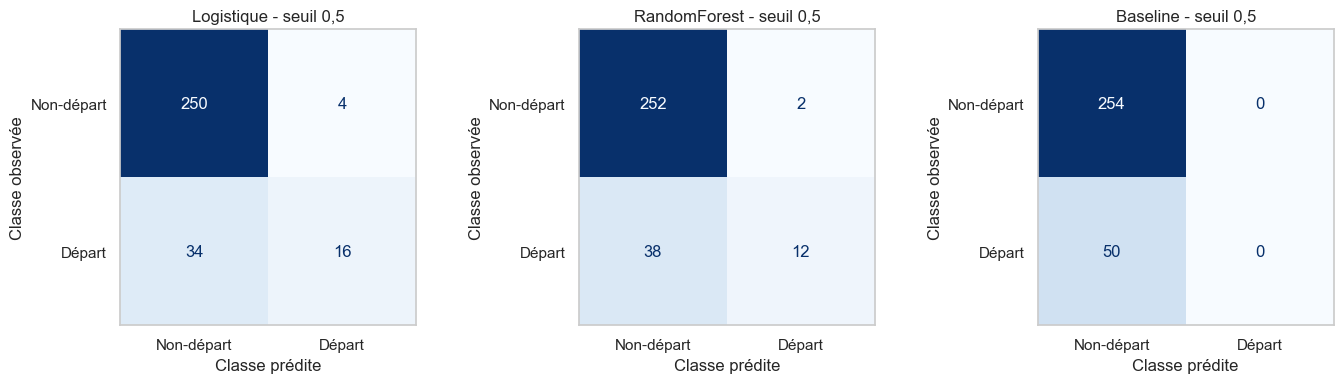

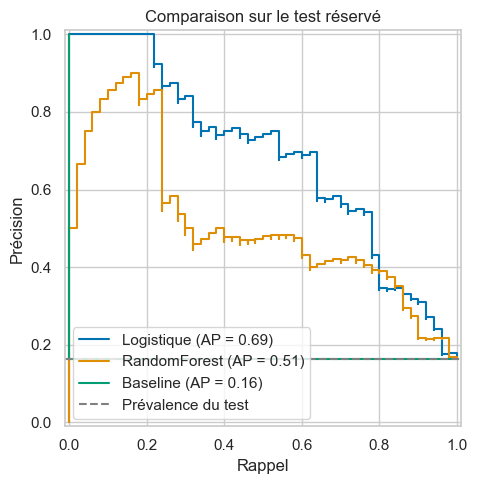

In [6]:
test_results, predictions = evaluate_test(searches, X_test, y_test)
comparison = pd.concat([cv_results, test_results], ignore_index=True)
display(export_table(comparison, "04_comparaison_performances"))
export_table(test_results, "04_evaluation")
plot_model_comparison(y_test, predictions)

## 6. Variables après transformation et sauvegarde
La liste des colonnes transformées provient des prétraitements ajustés sur l’entraînement complet, pas de tout le fichier. Elle peut différer des listes présentes dans certains plis lorsque des modalités rares y sont absentes.

Les trois pipelines sont sauvegardés en joblib. Le tableau d’indices conserve la position dans le dataset, la ligne Excel source, la partie, l’ordre dans chaque partie et le pli de validation. Les métadonnées enregistrent paramètres, versions et empreinte du fichier. Les prédictions individuelles du test ne sont pas exportées.

In [7]:
feature_names = transformed_features(searches)
display(export_table(feature_names, "04_variables_transformees"))
for name in ["Logistique", "RandomForest"]:
    pipeline = searches[name].best_estimator_
    names = feature_names.loc[feature_names.modele.eq(name), "variable_transformee"]
    assert len(names) == pipeline.named_steps["modele"].n_features_in_
    print(name, ":", len(names), "colonnes après transformation")
metadata = save_artifacts(searches, split_rows)
print("Pipelines et indices sauvegardés dans", MODEL_DIR.relative_to(ROOT))
print(json.dumps(metadata, ensure_ascii=False, indent=2))

,modele,position,variable_transformee
0,Logistique,0,binaires__Gender
1,Logistique,1,binaires__OverTime
2,Logistique,2,categories_scores__BusinessTravel_Non-Travel
3,Logistique,3,categories_scores__BusinessTravel_Travel_Frequ...
4,Logistique,4,categories_scores__BusinessTravel_Travel_Rarely
...,...,...,...
137,RandomForest,44,quantitatives__TrainingTimesLastYear
138,RandomForest,45,quantitatives__YearsAtCompany
139,RandomForest,46,quantitatives__YearsInCurrentRole
140,RandomForest,47,quantitatives__YearsSinceLastPromotion


Logistique : 93 colonnes après transformation
RandomForest : 49 colonnes après transformation
Pipelines et indices sauvegardés dans outputs/models
{
  "fichier": "data/variantes/02_sans_colonnes_valeurs_inchangees.xlsx",
  "sha256_source": "ec3168d646775d47a4472d7fee640a5595ea48703c345c1ce0a06b28f8e14a66",
  "random_state": 42,
  "test_size": 0.2,
  "plis": 5,
  "seuil": 0.5,
  "selection": "average_precision",
  "python": "3.9.6",
  "pandas": "2.3.3",
  "numpy": "2.0.2",
  "scikit_learn": "1.6.1",
  "joblib": "1.5.3",
  "parametres": {
    "Logistique": {
      "modele__C": 0.1,
      "modele__class_weight": null
    },
    "RandomForest": {
      "modele__class_weight": null,
      "modele__max_depth": null,
      "modele__min_samples_leaf": 2
    },
    "Baseline": {}
  }
}


## 7. Vérifications finales de reproductibilité
Les modèles enregistrés sont rechargés et vérifiés sur un petit échantillon **d’entraînement**. On contrôle également l’apprentissage du scaler sur l’entraînement complet, les types de prétraitements et la reconstruction des indices sauvegardés. Toutes les empreintes Excel doivent rester inchangées.

In [8]:
import joblib
for name, search in searches.items():
    restored = joblib.load(MODEL_DIR / f"04_{name}.joblib")
    np.testing.assert_allclose(restored.predict_proba(X_train.iloc[:8]),
                               search.best_estimator_.predict_proba(X_train.iloc[:8]))
scaler = searches["Logistique"].best_estimator_.named_steps["preparation"].named_transformers_["quantitatives"]
np.testing.assert_allclose(scaler.mean_, X_train[quantitative].mean().to_numpy())
assert scaler.n_samples_seen_ == len(X_train)
for p, fingerprint in excel_hashes.items():
    assert sha256(p.read_bytes()).hexdigest() == fingerprint, f"Excel modifié : {p}"
saved = pd.read_csv(MODEL_DIR / "04_indices_split_plis.csv")
for part, expected_index in [("entrainement", X_train.index), ("test", X_test.index)]:
    positions = saved.loc[saved.partie.eq(part)].sort_values("ordre_dans_partie").position_dataset.to_numpy()
    np.testing.assert_array_equal(positions, expected_index.to_numpy())
for i, (_, validation) in enumerate(folds):
    saved_positions = saved.loc[saved.pli_validation.eq(i), "position_dataset"]
    assert set(saved_positions) == set(X_train.iloc[validation].index)
print("Contrôles réussis : sources intactes, split/plis communs, cibles exclues, sauvegardes relues.")

Contrôles réussis : sources intactes, split/plis communs, cibles exclues, sauvegardes relues.


## 8. Lecture et limites

- Les deux modèles sont comparés avec le même protocole ; leurs scores test ne servent ni à régler les hyperparamètres ni à choisir un seuil. Les performances restent incertaines avec un seul découpage et peu de départs dans le test.
- La pondération `balanced` change l’apprentissage. **Les probabilités d’un modèle pondéré ne sont pas automatiquement des risques bien calibrés.** Aucune calibration n’est effectuée ici.
- Les scores hors échelle et incohérences d’ancienneté sont volontairement conservés dans cette version. La forêt utilise leur ordre numérique ; la logistique les traite en catégories. Leur impact mérite une analyse de sensibilité ultérieure.
- La disponibilité des variables avant le départ n’est pas établie : une fuite temporelle reste possible malgré un prétraitement sans fuite entre entraînement et test. On ne démontre pas les causes des départs, une discrimination ou l’efficacité d’une action RH.
- L’absence de pays, de dates et de données d’absence limite la transposition à l’Afrique et empêche la mesure de l’absentéisme. `YearsSinceLastPromotion` reste un délai, pas un taux de promotion.
- Le guide PDF et les éventuels exports archivés de l’ancien notebook 04 décrivent la précédente analyse 75/25 ; ils ne constituent pas les résultats de ce protocole.
